# 03 — Model Training

Trains two AutoGluon models:
- **W/D/L Classifier** — predicts match result (win / draw / loss) using `log_loss`
- **Goal Difference Regressor** — predicts `home_score - away_score` using `mean_absolute_error`

Validation: 2022 FIFA World Cup matches (2022-11-20 → 2022-12-18).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from autogluon.tabular import TabularPredictor

import matplotlib.pyplot as plt

In [2]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(exist_ok=True)

# Load training set
df = pd.read_csv(PROCESSED_DIR / "training_set.csv", parse_dates=["date"])

# Validation: use 2026 matches (most recent, highest quality)
# Train on 2023-2025
val_mask  = df["date"].dt.year == 2026
train_df  = df[~val_mask].copy()
val_df    = df[val_mask].copy()

print(f"Train rows : {len(train_df):,} (2023-2025)")
print(f"Val rows   : {len(val_df):,}  (2026 matches)")
print()
print("Train result distribution:")
print(train_df["result"].value_counts(normalize=True).rename("share").to_string())
print()
print("Val result distribution:")
print(val_df["result"].value_counts(normalize=True).rename("share").to_string())

Train rows : 3,287 (2023-2025)
Val rows   : 276  (2026 matches)

Train result distribution:
result
W    0.470338
L    0.301491
D    0.228172

Val result distribution:
result
D    0.442029
W    0.365942
L    0.192029


In [3]:
# Columns to exclude from features
NON_FEATURE_COLS = {"date", "home_team", "away_team", "tournament", "result", "goal_diff", "sample_weight"}

feature_cols = [c for c in df.columns if c not in NON_FEATURE_COLS]

# Drop rows with NaN in labels (future matches with no scores yet)
train_df = train_df.dropna(subset=["result", "goal_diff"]).copy()
val_df = val_df.dropna(subset=["result", "goal_diff"]).copy()

# Fill NaN in rolling features with defaults
for col in ["goals_scored_avg_home", "goals_scored_avg_away", "goals_conceded_avg_home", "goals_conceded_avg_away"]:
    train_df[col] = train_df[col].fillna(1.0)
    val_df[col] = val_df[col].fillna(1.0)

print(f"After cleaning — Train: {len(train_df)}, Val: {len(val_df)}")
print(f"\nFeature columns ({len(feature_cols)}):")
for col in feature_cols:
    print(f"  {col:40s}  {str(df[col].dtype)}")

After cleaning — Train: 3287, Val: 204

Feature columns (15):
  elo_diff                                  int64
  fifa_rank_diff                            int64
  fifa_points_diff                          float64
  squad_value_ratio                         float64
  form_home                                 float64
  form_away                                 float64
  goals_scored_avg_home                     float64
  goals_scored_avg_away                     float64
  goals_conceded_avg_home                   float64
  goals_conceded_avg_away                   float64
  h2h_wins                                  float64
  match_importance                          float64
  confederation_home                        object
  confederation_away                        object
  neutral_venue                             int64


In [4]:
clf_train = train_df[feature_cols + ["result", "sample_weight"]].copy()
clf_val   = val_df[feature_cols + ["result"]].copy()

predictor_clf = TabularPredictor(
    label="result",
    eval_metric="log_loss",
    sample_weight="sample_weight",
    path=str(MODELS_DIR / "classifier"),
)
predictor_clf.fit(
    clf_train,
    presets="best_quality",
    time_limit=600,
)

print("\n=== Classifier leaderboard (validation set) ===")
leaderboard_clf = predictor_clf.leaderboard(clf_val, silent=True)
print(leaderboard_clf[["model", "score_val", "score_test"]].to_string(index=False))

Verbosity: 2 (Standard Logging)


=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.3
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Mon Dec  1 20:46:23 UTC 2025
CPU Count:          14
Pytorch Version:    2.9.1+cu128
CUDA Version:       CUDA is not available
Memory Avail:       9.76 GB / 15.34 GB (63.6%)
Disk Space Avail:   885.47 GB / 1006.85 GB (87.9%)


Presets specified: ['best_quality']


Using hyperparameters preset: hyperparameters='zeroshot'


Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)


Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1


... (1,934 outputs left out)

AutoGluon training complete, total runtime = 138.52s ... Best model: WeightedEnsemble_L3 | Estimated inference throughput: 2625.0 rows/s (3287 batch size)


TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/home/hanz/2026-fifa-worldcup-prediction/models/classifier")



=== Classifier leaderboard (validation set) ===


                   model  score_val  score_test
RandomForest_r195_BAG_L2  -0.867525   -0.794693
 RandomForest_r39_BAG_L2  -0.862153   -0.797902
 RandomForest_r16_BAG_L2  -0.865312   -0.799839
 RandomForest_r34_BAG_L2  -0.850577   -0.800195
 RandomForest_r15_BAG_L2  -0.856117   -0.800231
 RandomForestEntr_BAG_L2  -0.861397   -0.804256
     WeightedEnsemble_L3  -0.835269   -0.804721
   ExtraTrees_r42_BAG_L2  -0.848007   -0.805532
RandomForest_r166_BAG_L2  -0.857629   -0.805604
RandomForest_r127_BAG_L2  -0.849624   -0.806155
    ExtraTrees_r4_BAG_L2  -0.848761   -0.810680
 RandomForestGini_BAG_L2  -0.867757   -0.811591
   ExtraTrees_r49_BAG_L2  -0.843886   -0.811691
   ExtraTreesGini_BAG_L2  -0.843886   -0.811691
 RandomForest_r34_BAG_L1  -0.850258   -0.812703
  ExtraTrees_r178_BAG_L2  -0.843323   -0.814125
  ExtraTrees_r172_BAG_L2  -0.848407   -0.814454
  ExtraTrees_r126_BAG_L2  -0.845515   -0.815320
     WeightedEnsemble_L2  -0.846543   -0.818049
  ExtraTrees_r197_BAG_L2  -0.844526   -0

In [5]:
from sklearn.metrics import accuracy_score

clf_val_features = clf_val.drop(columns=["result"])
y_true = clf_val["result"]
y_pred = predictor_clf.predict(clf_val_features)

acc = accuracy_score(y_true, y_pred)
print(f"Accuracy on 2022 WC validation set: {acc:.3f}")
print()

pred_dist   = y_pred.value_counts(normalize=True).rename("predicted")
actual_dist = y_true.value_counts(normalize=True).rename("actual")
dist_df = pd.concat([actual_dist, pred_dist], axis=1).fillna(0)
print("Result distribution — actual vs predicted:")
print(dist_df.to_string())

Accuracy on 2022 WC validation set: 0.637

Result distribution — actual vs predicted:
          actual  predicted
result                     
W       0.495098   0.686275
L       0.259804   0.294118
D       0.245098   0.019608


In [6]:
reg_train = train_df[feature_cols + ["goal_diff", "sample_weight"]].copy()
reg_val   = val_df[feature_cols + ["goal_diff"]].copy()

predictor_reg = TabularPredictor(
    label="goal_diff",
    problem_type="regression",
    eval_metric="mean_absolute_error",
    sample_weight="sample_weight",
    path=str(MODELS_DIR / "regressor"),
)
predictor_reg.fit(
    reg_train,
    presets="best_quality",
    time_limit=600,
)

print("\n=== Regressor leaderboard (validation set) ===")
leaderboard_reg = predictor_reg.leaderboard(reg_val, silent=True)
print(leaderboard_reg[["model", "score_val", "score_test"]].to_string(index=False))

Verbosity: 2 (Standard Logging)


=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.3
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Mon Dec  1 20:46:23 UTC 2025
CPU Count:          14
Pytorch Version:    2.9.1+cu128
CUDA Version:       CUDA is not available
Memory Avail:       9.60 GB / 15.34 GB (62.6%)
Disk Space Avail:   884.31 GB / 1006.85 GB (87.8%)


Presets specified: ['best_quality']


Using hyperparameters preset: hyperparameters='zeroshot'


Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)


Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1


... (1,442 outputs left out)

AutoGluon training complete, total runtime = 63.91s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 3825.8 rows/s (3287 batch size)


TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/home/hanz/2026-fifa-worldcup-prediction/models/regressor")



=== Regressor leaderboard (validation set) ===


                   model  score_val  score_test
  ExtraTrees_r178_BAG_L1  -1.319297   -1.264858
 RandomForest_r34_BAG_L1  -1.336150   -1.268426
   ExtraTrees_r42_BAG_L1  -1.327440   -1.268944
  ExtraTrees_r172_BAG_L1  -1.320850   -1.269255
    ExtraTrees_r4_BAG_L1  -1.320551   -1.271256
     WeightedEnsemble_L2  -1.312279   -1.272532
  ExtraTrees_r197_BAG_L1  -1.337263   -1.277845
    ExtraTreesMSE_BAG_L1  -1.337263   -1.277845
  ExtraTrees_r126_BAG_L1  -1.315733   -1.281277
   ExtraTrees_r49_BAG_L1  -1.326508   -1.288167
 RandomForest_r15_BAG_L1  -1.343217   -1.291578
RandomForest_r166_BAG_L1  -1.331887   -1.293062
RandomForest_r127_BAG_L1  -1.345243   -1.297680
 RandomForest_r39_BAG_L1  -1.343590   -1.300886
RandomForest_r195_BAG_L1  -1.344737   -1.304964
 RandomForest_r16_BAG_L1  -1.356723   -1.314012
  RandomForestMSE_BAG_L1  -1.356723   -1.314012


In [7]:
reg_val_features = reg_val.drop(columns=["goal_diff"])
y_true_reg = reg_val["goal_diff"]
y_pred_reg = predictor_reg.predict(reg_val_features)

mae = np.mean(np.abs(y_true_reg - y_pred_reg))
print(f"MAE on 2022 WC validation set: {mae:.3f}")
print()

# Show predictions vs actuals for each WC match
comparison = val_df[["date", "home_team", "away_team", "goal_diff"]].copy().reset_index(drop=True)
comparison["pred_goal_diff"] = y_pred_reg.values
comparison["abs_error"] = (comparison["goal_diff"] - comparison["pred_goal_diff"]).abs()
comparison = comparison.sort_values("date").reset_index(drop=True)

print("2022 WC matches — actual vs predicted goal difference:")
print(comparison[["date", "home_team", "away_team", "goal_diff", "pred_goal_diff", "abs_error"]].to_string(index=False))

MAE on 2022 WC validation set: 1.273

2022 WC matches — actual vs predicted goal difference:
      date                    home_team                        away_team  goal_diff  pred_goal_diff  abs_error
2026-01-03                      Senegal                            Sudan        2.0        2.071644   0.071644
2026-01-03                         Mali                          Tunisia        0.0       -0.437899   0.437899
2026-01-04                      Morocco                         Tanzania        1.0        3.065315   2.065315
2026-01-04                 South Africa                         Cameroon       -1.0       -0.173579   0.826421
2026-01-05                        Egypt                            Benin        2.0        1.049532   0.950468
2026-01-05                      Nigeria                       Mozambique        4.0        1.791463   2.208537
2026-01-06                  Ivory Coast                     Burkina Faso        3.0        0.000326   2.999674
2026-01-06         

Computing feature importance via permutation shuffling for 15 features using 204 rows with 5 shuffle sets...


	125.96s	= Expected runtime (25.19s per shuffle set)


	9.27s	= Actual runtime (Completed 5 of 5 shuffle sets)


Computing feature importance via permutation shuffling for 15 features using 204 rows with 5 shuffle sets...


	35.54s	= Expected runtime (7.11s per shuffle set)


	4.4s	= Actual runtime (Completed 5 of 5 shuffle sets)


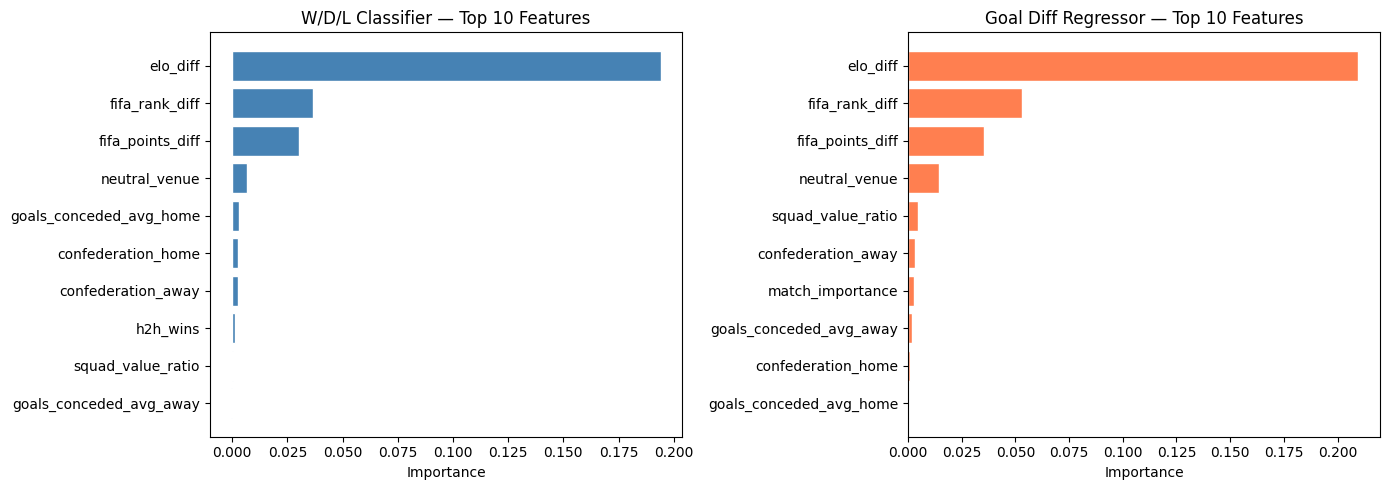

Feature importance plot saved to models/feature_importance.png


In [8]:
# Feature importance — top 10 for each model
fi_clf = predictor_clf.feature_importance(clf_val).head(10)
fi_reg = predictor_reg.feature_importance(reg_val).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(fi_clf.index[::-1], fi_clf["importance"][::-1], color="steelblue", edgecolor="white")
axes[0].set_title("W/D/L Classifier — Top 10 Features")
axes[0].set_xlabel("Importance")

axes[1].barh(fi_reg.index[::-1], fi_reg["importance"][::-1], color="coral", edgecolor="white")
axes[1].set_title("Goal Diff Regressor — Top 10 Features")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.savefig("../models/feature_importance.png", dpi=100, bbox_inches="tight")
plt.show()
print("Feature importance plot saved to models/feature_importance.png")